# Data Exploration and Cleaning

This notebook focuses on understanding the TB outcome dataset, identifying data quality issues, handling missing values, removing duplicates, and standardizing inconsistencies to prepare the data for analysis.





In [98]:
# import necessary dependancies
import duckdb
import pandas as pd
import seaborn as sns

In [41]:

data_path='../data/tb-outcomes.csv'


## Data Exploration

In [42]:
# display 5 first observation
duckdb.sql(f"""
           SELECT *
           FROM read_csv_auto('{data_path}')
           LIMIT 10
           """).fetchdf()

,patient_id,age,sex,region,diagnosis_date,hiv_status,diabetes,smear_result,drug_resistance,planned_months,weight_start_kg,weight_end_kg,adherence_pct,outcome,treatment_success
0,TB30000,44,Female,Capital,2022-07-15,Unknown,False,Negative,Drug-sensitive,6,55.5,59.3,90.9,Cured,1
1,TB30001,47,Male,South,2022-03-28,Negative,False,Not done,Drug-sensitive,6,51.7,53.3,73.5,Treatment completed,1
2,TB30002,19,Female,North,2021-10-08,HIV+,False,Negative,Drug-sensitive,6,66.7,73.7,74.6,Treatment completed,1
3,TB30003,20,Female,West,2023-05-10,Negative,False,Positive,Drug-sensitive,6,62.3,58.6,96.5,Died,0
4,TB30004,37,Male,South,2022-06-14,+,False,Positive,Drug-sensitive,6,48.9,54.1,79.9,Cured,1
5,TB30005,31,Male,East,09/03/2022,Positive,False,Negative,Drug-sensitive,6,67.2,69.3,91.2,Cured,1
6,TB30006,25,Female,South,08/09/2023,Negative,False,Not done,Drug-sensitive,6,63.1,65.6,53.9,Deceased,0
7,TB30007,26,Male,South,"Jan 12, 2022",Positive,False,Positive,Drug-sensitive,6,54.4,49.5,53.4,Lost to follow-up,0
8,TB30008,21,Male,North,01/03/2022,Negative,False,Positive,Drug-sensitive,6,42.3,47.5,NaN,Treatment completed,1
9,TB30009,63,Female,North,"Apr 03, 2022",-,False,Positive,Drug-sensitive,6,44.6,43.6,67.0,Cured,1


In [43]:
# count number of rows
duckdb.sql(f"""
           SELECT COUNT(*) as number_rows
           FROM  read_csv_auto('{data_path}')
           """).fetchdf().loc[0,'number_rows']

np.int64(3000)

In [44]:
# get general info of data
duckdb.sql(f"""
           DESCRIBE
           SELECT *
           FROM read_csv_auto('{data_path}')
           """).fetchdf()

,column_name,column_type,null,key,default,extra
0,patient_id,VARCHAR,YES,None,None,None
1,age,BIGINT,YES,None,None,None
2,sex,VARCHAR,YES,None,None,None
3,region,VARCHAR,YES,None,None,None
4,diagnosis_date,VARCHAR,YES,None,None,None
5,hiv_status,VARCHAR,YES,None,None,None
6,diabetes,BOOLEAN,YES,None,None,None
7,smear_result,VARCHAR,YES,None,None,None
8,drug_resistance,VARCHAR,YES,None,None,None
9,planned_months,BIGINT,YES,None,None,None


There are 3000 rows and 15 columns

In [45]:
# list all table columns
columns=duckdb.sql(
    f""" 
    DESCRIBE
    SELECT *
    FROM read_csv_auto('{data_path}')
    """
).fetchdf()["column_name"].tolist()

In [46]:
# calculate some of missing values per column
column_null_count={}
for col in columns:
    count=duckdb.sql(
        f""" 
        SELECT count('{col}') as {col}
        FROM read_csv_auto('{data_path}')
        WHERE {col} IS NULL
        """
    ).fetchdf()
  
    column_null_count[col]=int(count[col][0])
    
column_null_count

{'patient_id': 0,
 'age': 0,
 'sex': 0,
 'region': 0,
 'diagnosis_date': 0,
 'hiv_status': 0,
 'diabetes': 0,
 'smear_result': 0,
 'drug_resistance': 0,
 'planned_months': 0,
 'weight_start_kg': 0,
 'weight_end_kg': 300,
 'adherence_pct': 150,
 'outcome': 0,
 'treatment_success': 0}

In [47]:
# check for duplicates
duckdb.sql(
    f""" 
    SELECT COUNT(*)
    FROM (
        SELECT DISTINCT patient_id
        FROM read_csv_auto('{data_path}'))
    """
).fetchdf()

,count_star()
0,3000


There are no duplicate since they are 3000 rows and 3000 distinct rows

In [131]:
#  unique values per column
def get_distinct_values(source):
    unique_values=[]
    for col in columns:
        result=duckdb.sql(f"""
                SELECT DISTINCT {col}
                FROM {source}
                """).fetchdf()
        unique_values.append(result)
    return unique_values

In [134]:
get_distinct_values(f"read_csv_auto('{data_path}')")

[     patient_id
 0       TB30034
 1       TB30051
 2       TB30060
 3       TB30066
 4       TB30085
 ...         ...
 2995    TB32939
 2996    TB32943
 2997    TB32950
 2998    TB32951
 2999    TB32956
 
 [3000 rows x 1 columns],
     age
 0    31
 1    52
 2    32
 3    22
 4    15
 ..  ...
 79   58
 80   41
 81   76
 82    6
 83   82
 
 [84 rows x 1 columns],
       sex
 0  Female
 1    Male,
     region
 0  Capital
 1    North
 2     East
 3    South
 4     West,
      diagnosis_date
 0        2021-10-08
 1        2023-05-10
 2        2022-01-08
 3        10/12/2023
 4        2021-04-09
 ...             ...
 1769     2021-01-19
 1770     19/12/2023
 1771     15/04/2021
 1772     04/10/2022
 1773     2023-07-30
 
 [1774 rows x 1 columns],
     hiv_status
 0            -
 1          neg
 2            +
 3            ?
 4   Not tested
 5      Unknown
 6     Negative
 7         HIV+
 8     Positive
 9          pos
 10        HIV-,
    diabetes
 0      True
 1     False,
   smear_resul

In [49]:
# inspect rows with missing values
duckdb.sql(f"""
           SELECT *
           FROM read_csv_auto('{data_path}')
           WHERE weight_end_kg IS NULL
           OR adherence_pct IS NULL
;
           """)

patient_idVARCHAR,ageBIGINT,sexVARCHAR,regionVARCHAR,diagnosis_dateVARCHAR,hiv_statusVARCHAR,diabetesBOOLEAN,smear_resultVARCHAR,drug_resistanceVARCHAR,planned_monthsBIGINT,weight_start_kgDOUBLE,weight_end_kgDOUBLE,adherence_pctDOUBLE,outcomeVARCHAR,treatment_successBIGINT
TB30008,21,Male,North,01/03/2022,Negative,False,Positive,Drug-sensitive,6,42.3,47.5,NULL,Treatment completed,1
TB30021,44,Female,North,"May 12, 2023",Negative,False,Positive,Drug-sensitive,6,46.4,NULL,74.0,Cured,1
TB30025,43,Male,Capital,2023-11-07,Negative,False,Positive,Drug-sensitive,6,55.2,NULL,92.0,Cured,1
TB30032,52,Male,Capital,"Oct 23, 2021",neg,False,Negative,Drug-sensitive,6,49.5,NULL,80.5,Cured,1
TB30033,40,Male,Capital,28/09/2021,Negative,True,Negative,Drug-sensitive,6,68.5,73.3,NULL,Treatment completed,1
TB30038,70,Male,Capital,2021-01-16,Positive,False,Positive,Drug-sensitive,6,61.8,NULL,92.9,Cured,1
TB30057,50,Male,South,2022-01-02,Negative,False,Not done,Drug-sensitive,6,53.8,NULL,89.9,Treatment completed,1
TB30058,42,Male,South,30/11/2021,Negative,False,Positive,Drug-sensitive,6,38.8,NULL,82.6,Treatment completed,1
TB30062,9,Male,West,2021-11-17,Negative,False,Positive,Drug-sensitive,6,43.0,43.4,NULL,Cured,1
TB30081,30,Female,North,29/09/2021,Negative,False,Positive,Drug-sensitive,6,55.5,NULL,90.8,Cured,1


## Data Cleaning Tasks

The following data quality issues were identified during data exploration and will be addressed during cleaning:

1. **Standardize `hiv_status`:** The column contains inconsistent values representing HIV status, including `neg`, `Negative`, `HIV-`, `pos`, `Positive`, `HIV+`, `Not tested`, `Unknown`, and `?`, . Standardize these values into consistent categories while preserving unknown and untested statuses.

2. **Convert `diagnosis_date`:** Convert the `diagnosis_date` column from its current data type to a proper date format. 
3. `diagnosis_date` has different date format

4. **Handle missing values:** Investigate and address missing values in `weight_end_kg` and `adherence_pct`.

5. **Standardize drug resistance values:** Convert the drug resistance categories (`MDR` and `Drug Sensitive`) into Boolean values (`True` and `False`), respectively.

### Data Cleaning

<Axes: xlabel='weight_end_kg', ylabel='Count'>

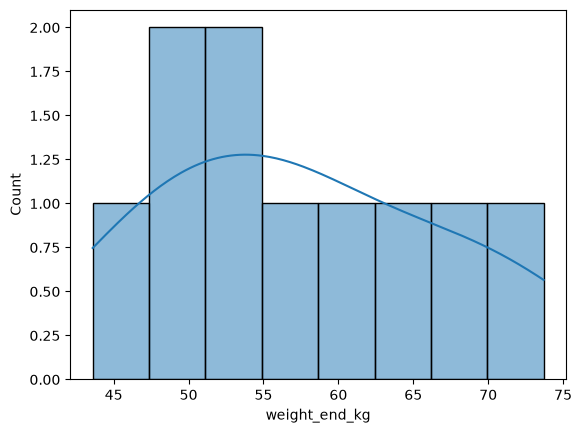

In [107]:
# distribution of weight_end_kg
df=duckdb.sql(f"""
           SELECT *
           FROM read_csv_auto('{data_path}')
           LIMIT 10
           """).fetchdf()
sns.histplot(df,x="weight_end_kg",bins=8,kde=True)

In [108]:
# weight_end statistical summary
df["weight_end_kg"].describe()

count    10.00000
mean     57.45000
std       9.76459
min      43.60000
25%      50.45000
50%      56.35000
75%      64.02500
max      73.70000
Name: weight_end_kg, dtype: float64

weight_end is slightly right skewed mean 57.45 and median 56.35 so i will use median to input since only 10% is missing

<Axes: xlabel='adherence_pct', ylabel='Count'>

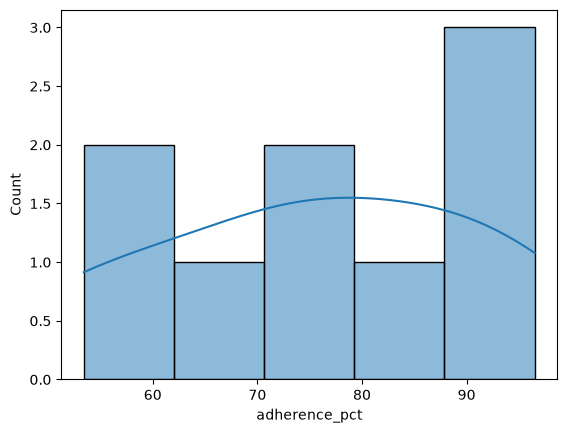

In [116]:
# distribution of adhrence_pct
sns.histplot(df,x='adherence_pct',bins=5,kde=True
	)

In [117]:
# statistical summary
df["adherence_pct"].describe()

count     9.000000
mean     75.655556
std      15.715527
min      53.400000
25%      67.000000
50%      74.600000
75%      90.900000
max      96.500000
Name: adherence_pct, dtype: float64

adherence_pct is slightly right skewed mean 57.45 and median 56.35 so i will use median to input since only 10% is missing

In [136]:
def wrangle_tb_outcome_data(csv_path):
    duckdb.sql(f"""
               CREATE OR REPLACE TABLE tb AS
               SELECT *
               FROM read_csv_auto('{csv_path}')
               """)
    duckdb.sql(
        """ 
        UPDATE tb
        SET hiv_status = CASE
            WHEN LOWER(TRIM(hiv_status)) IN ('neg','negative','hiv-','-')
                THEN 'Negative' 
            WHEN LOWER(TRIM(hiv_status)) IN ('pos','positive','hiv+','+')
                THEN 'Positive'
            WHEN LOWER(TRIM(hiv_status)) IN ('?','not tested','unknown')
                THEN 'Unknown'
            ELSE 'Unknown'
            END
        """
        
    )
    duckdb.sql(
        """ 
        UPDATE tb
        SET drug_resistance = CASE
        WHEN LOWER(TRIM(drug_resistance))='drug-sensitive'
            THEN False
        ELSE  True
        END
        
        """
    )
    
    duckdb.sql(
        """ 
        ALTER TABLE tb
        ALTER COLUMN diagnosis_date SET DATA TYPE DATE
        USING COALESCE(
            TRY_STRPTIME(diagnosis_date, '%d/%m/%Y'),
            TRY_STRPTIME(diagnosis_date, '%b %d, %Y'),
            TRY_STRPTIME(diagnosis_date, '%B %d, %Y'),
            TRY_STRPTIME(diagnosis_date, '%d-%m-%Y'),
            TRY_STRPTIME(diagnosis_date, '%Y-%m-%d')
        )::DATE
        
        """
    )
    duckdb.sql("""
               ALTER TABLE tb
               ALTER COLUMN drug_resistance SET DATA TYPE BOOLEAN
               """)
    duckdb.sql("""
               UPDATE tb
               SET weight_end_kg =(
                   SELECT MEDIAN(weight_end_kg)
                   FROM tb
               ) WHERE weight_end_kg IS NULL
               
               """)
    duckdb.sql("""
               UPDATE tb
               SET adherence_pct = (
                                  SELECT MEDIAN(adherence_pct)
                                  FROM tb
                              )WHERE adherence_pct IS NULL
               """)
    
    return duckdb.sql("SELECT * FROM tb").fetchdf()

    
    

In [137]:
wrangle_tb_outcome_data(data_path)

,patient_id,age,sex,region,diagnosis_date,hiv_status,diabetes,smear_result,drug_resistance,planned_months,weight_start_kg,weight_end_kg,adherence_pct,outcome,treatment_success
0,TB30000,44,Female,Capital,2022-07-15,Unknown,False,Negative,False,6,55.5,59.3,90.9,Cured,1
1,TB30001,47,Male,South,2022-03-28,Negative,False,Not done,False,6,51.7,53.3,73.5,Treatment completed,1
2,TB30002,19,Female,North,2021-10-08,Positive,False,Negative,False,6,66.7,73.7,74.6,Treatment completed,1
3,TB30003,20,Female,West,2023-05-10,Negative,False,Positive,False,6,62.3,58.6,96.5,Died,0
4,TB30004,37,Male,South,2022-06-14,Positive,False,Positive,False,6,48.9,54.1,79.9,Cured,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,TB32995,37,Female,North,2022-06-23,Negative,True,Negative,False,6,47.8,50.0,44.8,Treatment completed,1
2996,TB32996,36,Male,South,2023-12-08,Unknown,False,Positive,False,6,52.3,54.8,90.3,Treatment completed,1
2997,TB32997,30,Male,North,2022-07-16,Negative,True,Negative,False,6,63.8,71.0,78.6,Cured,1
2998,TB32998,59,Female,East,2022-05-12,Negative,False,Not done,False,6,64.6,68.0,86.5,Treatment completed,1


## Reinspect to ensure your data is clean

In [124]:
# display first 10 rows
duckdb.sql(""" 
           SELECT *
           FROM tb
           LIMIT 10
           """)

patient_idVARCHAR,ageBIGINT,sexVARCHAR,regionVARCHAR,diagnosis_dateDATE,hiv_statusVARCHAR,diabetesBOOLEAN,smear_resultVARCHAR,drug_resistanceBOOLEAN,planned_monthsBIGINT,weight_start_kgDOUBLE,weight_end_kgDOUBLE,adherence_pctDOUBLE,outcomeVARCHAR,treatment_successBIGINT
TB30000,44,Female,Capital,2022-07-15,Unknown,False,Negative,False,6,55.5,59.3,90.9,Cured,1
TB30001,47,Male,South,2022-03-28,Negative,False,Not done,False,6,51.7,53.3,73.5,Treatment completed,1
TB30002,19,Female,North,2021-10-08,Positive,False,Negative,False,6,66.7,73.7,74.6,Treatment completed,1
TB30003,20,Female,West,2023-05-10,Negative,False,Positive,False,6,62.3,58.6,96.5,Died,0
TB30004,37,Male,South,2022-06-14,Positive,False,Positive,False,6,48.9,54.1,79.9,Cured,1
TB30005,31,Male,East,2022-03-09,Positive,False,Negative,False,6,67.2,69.3,91.2,Cured,1
TB30006,25,Female,South,2023-09-08,Negative,False,Not done,False,6,63.1,65.6,53.9,Deceased,0
TB30007,26,Male,South,2022-01-12,Positive,False,Positive,False,6,54.4,49.5,53.4,Lost to follow-up,0
TB30008,21,Male,North,2022-03-01,Negative,False,Positive,False,6,42.3,47.5,87.0,Treatment completed,1
TB30009,63,Female,North,2022-04-03,Negative,False,Positive,False,6,44.6,43.6,67.0,Cured,1


In [138]:
# confirm you have a rows
duckdb.sql("""
           SELECT COUNT(*)
           FROM tb
           """)

count_star()BIGINT
3000


In [139]:
# confirm columns are of the same data type
duckdb.sql("""
           DESCRIBE tb
           """).fetchdf()


,column_name,column_type,null,key,default,extra
0,patient_id,VARCHAR,YES,None,None,None
1,age,BIGINT,YES,None,None,None
2,sex,VARCHAR,YES,None,None,None
3,region,VARCHAR,YES,None,None,None
4,diagnosis_date,DATE,YES,None,None,None
5,hiv_status,VARCHAR,YES,None,None,None
6,diabetes,BOOLEAN,YES,None,None,None
7,smear_result,VARCHAR,YES,None,None,None
8,drug_resistance,BOOLEAN,YES,None,None,None
9,planned_months,BIGINT,YES,None,None,None


In [140]:
# check for null values
missing_value_pct=[]
for col in columns:
    result=duckdb.sql(f"""
               SELECT 100-COUNT({col}) * 100/COUNT(*) as {col}
               FROM tb
               
               """).fetchdf()
 
    missing_value_pct.append({col:int(result.loc[0,col])})
missing_value_pct
    

[{'patient_id': 0},
 {'age': 0},
 {'sex': 0},
 {'region': 0},
 {'diagnosis_date': 0},
 {'hiv_status': 0},
 {'diabetes': 0},
 {'smear_result': 0},
 {'drug_resistance': 0},
 {'planned_months': 0},
 {'weight_start_kg': 0},
 {'weight_end_kg': 0},
 {'adherence_pct': 0},
 {'outcome': 0},
 {'treatment_success': 0}]

In [141]:
# get distinct values per column
get_distinct_values("tb")

[     patient_id
 0       TB30008
 1       TB30018
 2       TB30046
 3       TB30067
 4       TB30068
 ...         ...
 2995    TB32903
 2996    TB32942
 2997    TB32970
 2998    TB32977
 2999    TB32990
 
 [3000 rows x 1 columns],
     age
 0    44
 1    17
 2     9
 3    30
 4    14
 ..  ...
 79   71
 80   25
 81   21
 82   87
 83   53
 
 [84 rows x 1 columns],
       sex
 0  Female
 1    Male,
     region
 0    South
 1  Capital
 2    North
 3     West
 4     East,
      diagnosis_date
 0        2023-12-01
 1        2022-07-08
 2        2021-09-28
 3        2021-05-26
 4        2022-04-23
 ...             ...
 1020     2022-09-06
 1021     2022-10-28
 1022     2021-11-23
 1023     2022-11-10
 1024     2022-10-22
 
 [1025 rows x 1 columns],
   hiv_status
 0    Unknown
 1   Negative
 2   Positive,
    diabetes
 0     False
 1      True,
   smear_result
 0     Positive
 1     Not done
 2     Negative,
    drug_resistance
 0            False
 1             True,
    planned_months
 0   

In [143]:
df.to_csv("../data/cleaned_tb_outcome.csv",index=False)